## ETL Process

In [ ]:
import pandas as pd

mr_df = pd.read_json("medical_records.json")

df1 = mr_df.copy()

In [ ]:
querry = pd.read_json("queries.json")

df2 = querry.copy()

## Data Cleaning & Validation

In [ ]:
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

In [ ]:
print(df1.columns.tolist())
print(df2.columns.tolist())

['record_id', 'note_text', 'category', 'subcategory', 'visit_type', 'patient_age', 'patient_sex', 'source']
['query_id', 'query_text', 'query_type', 'relevant_record_ids']


In [ ]:
df1 = df1.map(lambda x: x.strip() if isinstance(x, str) else x)
df2 = df2.map(lambda x: x.strip() if isinstance(x, str) else x)

In [ ]:
print("Medical Records Shape:", df1.shape)
print("Query Dataset Shape:", df2.shape)

Medical Records Shape: (298, 8)
Query Dataset Shape: (57, 4)


#### Medical Records:  Data Cleaning

In [ ]:
df1.head()

,record_id,note_text,category,subcategory,visit_type,patient_age,patient_sex,source
0,MR0001,Deep laceration to the palm from a box cutter ...,dermatological,laceration,ED visit,23,M,synthetic_pi_case_files
1,MR0002,S: Chronic acid reflux despite over-the-counte...,gastrointestinal,gerd,gastroenterology consult,34,F,synthetic_clinical_notes
2,MR0003,Patient reports right shoulder pain and weakne...,musculoskeletal,rotator_cuff_injury,ED visit,73,M,synthetic_pi_case_files
3,MR0004,Episodes of sudden intense fear with chest tig...,psychiatric,generalized_anxiety,behavioral health visit,56,M,synthetic_clinical_notes
4,MR0005,37-year-old female. Known HFrEF presenting wit...,cardiovascular,heart_failure,ED visit,37,F,synthetic_clinical_notes


In [ ]:
df1.dtypes

,0
record_id,object
note_text,object
category,object
subcategory,object
visit_type,object
patient_age,object
patient_sex,object
source,object


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298 entries, 0 to 297
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   record_id    298 non-null    object
 1   note_text    295 non-null    object
 2   category     292 non-null    object
 3   subcategory  298 non-null    object
 4   visit_type   298 non-null    object
 5   patient_age  293 non-null    object
 6   patient_sex  296 non-null    object
 7   source       295 non-null    object
dtypes: object(8)
memory usage: 18.8+ KB


In [ ]:
df1.describe()

,record_id,note_text,category,subcategory,visit_type,patient_age,patient_sex,source
count,298,295,292,298,298,293,296,295
unique,297,288,16,34,18,69,5,2
top,MR0045,,musculoskeletal,concussion_tbi,primary care follow-up,77,F,synthetic_clinical_notes
freq,2,5,60,11,59,12,149,235


In [ ]:
for i in df1.columns:
    print(f"{i} :{df1[i].isnull().sum()}")

record_id :0
note_text :3
category :6
subcategory :0
visit_type :0
patient_age :5
patient_sex :2
source :3


In [ ]:
df1.duplicated().sum()

np.int64(0)

In [ ]:
import warnings
warnings.filterwarnings('ignore')
warnings.warn('This function is deprecated.', DeprecationWarning)

In [ ]:
# Remove the Duplicate in Record_id

print(df1["record_id"].duplicated().sum())
print("Before Removing the Duplicates:", df1.shape)
df1.drop_duplicates(subset="record_id", keep= "first", inplace=True)
print("After Removing the Duplicates:", df1.shape)

1
Before Removing the Duplicates: (298, 8)
After Removing the Duplicates: (297, 8)


In [ ]:
# Checking for Null Values in note_text
df1[
    df1["note_text"].isna() |
    df1["note_text"].astype(str).str.strip().eq("")
]

,record_id,note_text,category,subcategory,visit_type,patient_age,patient_sex,source
40,MR0042,,dermatological,cellulitis,primary care follow-up,45,M,synthetic_clinical_notes
63,MR0064,None,cardiovascular,atrial_fibrillation,primary care follow-up,66,F,synthetic_clinical_notes
92,MR0093,NaN,musculoskeletal,ankle_sprain,urgent care,43,F,synthetic_clinical_notes
124,MR0125,,neurological,concussion_tbi,neurology consult,75,F,synthetic_pi_case_files
159,MR0160,,dermatological,contact_dermatitis,dermatology consult,65,F,synthetic_clinical_notes
212,MR0213,,respiratory,asthma_exacerbation,primary care follow-up,32,M,synthetic_clinical_notes
244,MR0245,None,cardiovascular,hypertension_followup,primary care follow-up,25,M,synthetic_clinical_notes
255,MR0256,,psychiatric,generalized_anxiety,telehealth visit,63,M,synthetic_clinical_notes


In [ ]:
blank_notes = df1[df1["note_text"].isna() | df1["note_text"].astype(str).str.strip().eq("")]

print("Blank notes:", len(blank_notes))

Blank notes: 8


In [ ]:
df1.drop(blank_notes.index, axis = 0, inplace =True)
print(df1.shape)

(289, 8)


In [ ]:
blank_category = df1[df1["category"].isna() | df1["category"].astype(str).str.strip().eq("")]

In [ ]:
df1.loc[blank_category.index, "category"] = "Unknown"

In [ ]:
for i in df1.columns:
    print(f"{i}:", df1[i].isna().sum())

record_id: 0
note_text: 0
category: 0
subcategory: 0
visit_type: 0
patient_age: 5
patient_sex: 2
source: 3


#### Queries : Data Cleaning

In [ ]:
df2.head()

,query_id,query_text,query_type,relevant_record_ids
0,Q001,"wheezing and tight chest, needing rescue inhal...",paraphrase,"[MR0049, MR0079, MR0086, MR0105, MR0141, MR015..."
1,Q002,fever with productive cough and lung infection...,paraphrase,"[MR0037, MR0047, MR0091, MR0132, MR0137, MR021..."
2,Q003,longtime smoker getting more breathless with m...,paraphrase,"[MR0075, MR0097, MR0109, MR0144, MR0149, MR015..."
3,Q004,cold symptoms with stuffy nose and sore throat,paraphrase,"[MR0028, MR0068, MR0134, MR0165, MR0182, MR020..."
4,Q005,chest pressure spreading to the arm with sweating,paraphrase,"[MR0018, MR0021, MR0069, MR0098, MR0145, MR018..."


In [ ]:
df2.dtypes

,0
query_id,object
query_text,object
query_type,object
relevant_record_ids,object


In [ ]:
for i in df2.columns:
    print(i, df2[i].duplicated().sum())

query_id 0
query_text 1
query_type 47
relevant_record_ids 19


In [ ]:
df2.isnull().sum()

,0
query_id,0
query_text,0
query_type,0
relevant_record_ids,0


In [ ]:
df2[df2["query_id"].duplicated(keep=False)]

,query_id,query_text,query_type,relevant_record_ids


In [ ]:
df2[df2["query_text"].duplicated(keep=False)]

,query_id,query_text,query_type,relevant_record_ids
53,Q054,,edge_case_empty,[]
54,Q055,,edge_case_whitespace,[]


In [ ]:
df2.head()

,query_id,query_text,query_type,relevant_record_ids
0,Q001,"wheezing and tight chest, needing rescue inhal...",paraphrase,"[MR0049, MR0079, MR0086, MR0105, MR0141, MR015..."
1,Q002,fever with productive cough and lung infection...,paraphrase,"[MR0037, MR0047, MR0091, MR0132, MR0137, MR021..."
2,Q003,longtime smoker getting more breathless with m...,paraphrase,"[MR0075, MR0097, MR0109, MR0144, MR0149, MR015..."
3,Q004,cold symptoms with stuffy nose and sore throat,paraphrase,"[MR0028, MR0068, MR0134, MR0165, MR0182, MR020..."
4,Q005,chest pressure spreading to the arm with sweating,paraphrase,"[MR0018, MR0021, MR0069, MR0098, MR0145, MR018..."


In [ ]:
df2["relevant_record_ids"].apply(tuple).duplicated().sum()

np.int64(19)

In [ ]:
df2["relevant_record_ids"].apply(tuple).isna().sum()

np.int64(0)

In [ ]:
# Check Unique ID in query_id

print("Total Queries:", len(df2))

print("Unique Query IDs:", df2["query_id"].nunique())

print(
    "Duplicate Query IDs:",
    df2["query_id"].duplicated().sum()
)

Total Queries: 57
Unique Query IDs: 57
Duplicate Query IDs: 0


In [ ]:
# Check the Invalid Values in Relevant Record ID

record_ids = set(df1["record_id"])

def find_invalid_ids(ids):
    if not isinstance(ids, list):
        return None

    return [rid for rid in ids if rid not in record_ids]


invalid_refs = df2.copy()

invalid_refs["invalid_record_ids"] = (
    invalid_refs["relevant_record_ids"].apply(find_invalid_ids)
)

invalid_refs = invalid_refs[invalid_refs["invalid_record_ids"].apply(lambda x: x is not None and len(x) > 0)]

print(invalid_refs[["query_id", "query_text", "invalid_record_ids"]])

   query_id                      query_text invalid_record_ids
56     Q057  painful urination with urgency           [MR9999]


In [ ]:
# Check missing values in query text

print(f"Query text Null Values:",df2["query_text"].isnull().sum())

# Check empty strings
empty_query_text = df2[
    df2["query_text"].apply(
        lambda x: isinstance(x, str) and x.strip() == ""
    )
]

display(empty_query_text)

Query text Null Values: 0


,query_id,query_text,query_type,relevant_record_ids
53,Q054,,edge_case_empty,[]
54,Q055,,edge_case_whitespace,[]


## Importing MiniLM-L6-v2 Sentance Embedding

In [ ]:
%pip install -U sentence-transformers

In [ ]:
import torch
import pandas as pd

from sentence_transformers import SentenceTransformer

In [ ]:
print("PyTorch Version:", torch.__version__)

print("Sentence Transformers Version:")
import sentence_transformers
print(sentence_transformers.__version__)

# Check available device
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Available Device:", device)

PyTorch Version: 2.11.0+cpu
Sentence Transformers Version:
6.2.0
Available Device: cpu


In [ ]:
model_names = {
    "MiniLM": "sentence-transformers/all-MiniLM-L6-v2",

    "MPNet": "sentence-transformers/all-mpnet-base-v2",

    "S-PubMedBERT": "pritamdeka/S-PubMedBert-MS-MARCO"
}

In [ ]:
# Dictionary to store loaded models

models = {}

# Load each pretrained model

for name, model_id in model_names.items():

    print(f"\nLoading {name}...")

    model = SentenceTransformer(
        model_id,
        device=device
    )

    models[name] = model

    print(f"{name} Loaded Successfully!")

print("\nAll Three Models Loaded Successfully.")


Loading MiniLM...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MiniLM Loaded Successfully!

Loading MPNet...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNet Loaded Successfully!

Loading S-PubMedBERT...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

S-PubMedBERT Loaded Successfully!

All Three Models Loaded Successfully.


In [ ]:
model_details = []

for name, model in models.items():

    model_details.append({

        "Model": name,

        "Embedding Dimension":
            model.get_sentence_embedding_dimension(),

        "Maximum Sequence Length":
            model.max_seq_length,

        "Device":
            str(next(model.parameters()).device),

        "Number of Parameters":
            sum(p.numel() for p in model.parameters()),

        "Pooling":
            [
                type(module).__name__
                for module in model.children()
            ]

    })

model_info = pd.DataFrame(model_details)

display(model_info)

,Model,Embedding Dimension,Maximum Sequence Length,Device,Number of Parameters,Pooling
0,MiniLM,384,256,cpu,22713216,"[Transformer, Pooling, Normalize]"
1,MPNet,768,384,cpu,109486464,"[Transformer, Pooling, Normalize]"
2,S-PubMedBERT,768,350,cpu,109482240,"[Transformer, Pooling]"


## Tokenization and Embedding


In [44]:
# Tokenization and Embedding using MiniLM

record_texts = df1["note_text"].tolist()
query_texts = df2["query_text"].tolist()

# Select MiniLM model
model = models["MiniLM"]

# Generate record embeddings
record_embeddings = model.encode(
    record_texts,
    show_progress_bar=True,
    convert_to_numpy=True
)

# Generate query embeddings
query_embeddings = model.encode(
    query_texts,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("MiniLM Embedding Completed!")
print("Record Embeddings Shape:", record_embeddings.shape)
print("Query Embeddings Shape:", query_embeddings.shape)

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

MiniLM Embedding Completed!
Record Embeddings Shape: (289, 384)
Query Embeddings Shape: (57, 384)


In [46]:
from sklearn.decomposition import PCA

# Store all dimensionality experiments
dimensionality_results = {
    "Native_384D": {
        "records": record_embeddings,
        "queries": query_embeddings
    }
}

# PCA experiments
for dimensions in [128, 64]:

    pca = PCA(n_components=dimensions)

    record_reduced = pca.fit_transform(record_embeddings)
    query_reduced = pca.transform(query_embeddings)

    dimensionality_results[f"PCA_{dimensions}D"] = {
        "records": record_reduced,
        "queries": query_reduced
    }

    print(f"\nPCA {dimensions}D Completed")
    print("Record Shape:", record_reduced.shape)
    print("Query Shape:", query_reduced.shape)
    print("Explained Variance:", pca.explained_variance_ratio_.sum())

print("\nAll Dimensionality Experiments Completed!")


PCA 128D Completed
Record Shape: (289, 128)
Query Shape: (57, 128)
Explained Variance: 0.97080874

PCA 64D Completed
Record Shape: (289, 64)
Query Shape: (57, 64)
Explained Variance: 0.86515474

All Dimensionality Experiments Completed!


In [47]:
for name, data in dimensionality_results.items():
    print(f"{name}:")
    print("Records:", data["records"].shape)
    print("Queries:", data["queries"].shape)

Native_384D:
Records: (289, 384)
Queries: (57, 384)
PCA_128D:
Records: (289, 128)
Queries: (57, 128)
PCA_64D:
Records: (289, 64)
Queries: (57, 64)


## Calculate Cosine Similarity & Dot Product in Unnormalized

In [48]:
dm = pd.DataFrame(dimensionality_results)

In [49]:
dm

,Native_384D,PCA_128D,PCA_64D
records,"[[-0.05011792, 0.123074606, 0.024109688, -0.02...","[[-0.29102275, 0.16706751, 0.13509741, -0.0374...","[[-0.29102275, 0.16706751, 0.13509741, -0.0374..."
queries,"[[-0.0061432477, 0.05719052, -0.002784208, -0....","[[0.32112566, -0.4239258, -0.28139597, 0.11936...","[[0.32112566, -0.4239258, -0.28139597, 0.11936..."


In [50]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_results = {}

for name, data in dimensionality_results.items():

    similarity = cosine_similarity(
        data["queries"],
        data["records"]
    )

    cosine_results[name] = similarity

    print(f"\n{name}")
    print("Similarity Matrix Shape:", similarity.shape)
    print("Highest Similarity:", similarity.max())
    print("Lowest Similarity:", similarity.min())


Native_384D
Similarity Matrix Shape: (57, 289)
Highest Similarity: 0.78011596
Lowest Similarity: -0.15855414

PCA_128D
Similarity Matrix Shape: (57, 289)
Highest Similarity: 0.80486447
Lowest Similarity: -0.3940177

PCA_64D
Similarity Matrix Shape: (57, 289)
Highest Similarity: 0.8434232
Lowest Similarity: -0.46295458


#### Dot Product

In [51]:
from sklearn.metrics.pairwise import linear_kernel

dot_product_results = {}

for name, data in dimensionality_results.items():

    similarity = linear_kernel(
        data["queries"],
        data["records"]
    )

    dot_product_results[name] = similarity

    print(f"\n{name}")
    print("Similarity Matrix Shape:", similarity.shape)
    print("Highest Similarity:", similarity.max())
    print("Lowest Similarity:", similarity.min())

print("\nAll Dot Product Experiments Completed!")


Native_384D
Similarity Matrix Shape: (57, 289)
Highest Similarity: 0.78011596
Lowest Similarity: -0.15855414

PCA_128D
Similarity Matrix Shape: (57, 289)
Highest Similarity: 0.68526965
Lowest Similarity: -0.27489236

PCA_64D
Similarity Matrix Shape: (57, 289)
Highest Similarity: 0.5955075
Lowest Similarity: -0.26374272

All Dot Product Experiments Completed!


## Compare both Un-Normalized Cosine and Dot Product vs Normalized Dot product

In [52]:
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import linear_kernel

normalized_dot_results = {}

for name, data in dimensionality_results.items():

    records_norm = normalize(data["records"], norm="l2")
    queries_norm = normalize(data["queries"], norm="l2")

    similarity = linear_kernel(queries_norm, records_norm)

    normalized_dot_results[name] = similarity

    print(f"\n{name}")
    print("Highest Similarity:", similarity.max())
    print("Lowest Similarity:", similarity.min())


Native_384D
Highest Similarity: 0.78011596
Lowest Similarity: -0.15855414

PCA_128D
Highest Similarity: 0.80486447
Lowest Similarity: -0.3940177

PCA_64D
Highest Similarity: 0.8434232
Lowest Similarity: -0.46295458


## Rank Records by Similarity

In [53]:
similarity_results = {
    "Cosine": cosine_results,
    "Dot_Product": dot_product_results,
    "Normalized_Dot_Product": normalized_dot_results
}

In [55]:
import numpy as np

ranked_results = {}

for method, experiments in similarity_results.items():

    for dimension, similarity_matrix in experiments.items():

        ranked_indices = np.argsort(-similarity_matrix,axis=1)

        ranked_results[f"{method}_{dimension}"] = ranked_indices

        print(f"{method}_{dimension}: Ranking Completed")

print("\nAll Ranking Experiments Completed!")

Cosine_Native_384D: Ranking Completed
Cosine_PCA_128D: Ranking Completed
Cosine_PCA_64D: Ranking Completed
Dot_Product_Native_384D: Ranking Completed
Dot_Product_PCA_128D: Ranking Completed
Dot_Product_PCA_64D: Ranking Completed
Normalized_Dot_Product_Native_384D: Ranking Completed
Normalized_Dot_Product_PCA_128D: Ranking Completed
Normalized_Dot_Product_PCA_64D: Ranking Completed

All Ranking Experiments Completed!


In [56]:
record_ids = df1["record_id"].tolist()

In [57]:
top_indices = ranked_results["Cosine_Native_384D"][0]

for rank, index in enumerate(top_indices[:5], start=1):

    print(
        f"Rank: {rank} | "
        f"Record ID: {record_ids[index]} | "
        f"Similarity: {cosine_results['Native_384D'][0][index]:.4f}"
    )

Rank: 1 | Record ID: MR0049 | Similarity: 0.7449
Rank: 2 | Record ID: MR0235 | Similarity: 0.6607
Rank: 3 | Record ID: MR0210 | Similarity: 0.6251
Rank: 4 | Record ID: MR0149 | Similarity: 0.5848
Rank: 5 | Record ID: MR0075 | Similarity: 0.5809


## Top-K Retrieval

In [58]:
top_k_values = [1, 3, 5, 10]

top_k_results = {}

for experiment, rankings in ranked_results.items():
    top_k_results[experiment] = {}

    for k in top_k_values:
        top_k_results[experiment][k] = rankings[:, :k]

    print(f"{experiment}: Top-K retrieval completed")

print("\nAll Top-K Experiments Completed!")

Cosine_Native_384D: Top-K retrieval completed
Cosine_PCA_128D: Top-K retrieval completed
Cosine_PCA_64D: Top-K retrieval completed
Dot_Product_Native_384D: Top-K retrieval completed
Dot_Product_PCA_128D: Top-K retrieval completed
Dot_Product_PCA_64D: Top-K retrieval completed
Normalized_Dot_Product_Native_384D: Top-K retrieval completed
Normalized_Dot_Product_PCA_128D: Top-K retrieval completed
Normalized_Dot_Product_PCA_64D: Top-K retrieval completed

All Top-K Experiments Completed!


In [59]:
top_5_indices = top_k_results["Cosine_Native_384D"][5][0]

for rank, index in enumerate(top_5_indices, start=1):
    print(f"Rank: {rank} | Record ID: {record_ids[index]}")

Rank: 1 | Record ID: MR0049
Rank: 2 | Record ID: MR0235
Rank: 3 | Record ID: MR0210
Rank: 4 | Record ID: MR0149
Rank: 5 | Record ID: MR0075


In [60]:
print("Query ID:", df2["query_id"].iloc[0])
print("Relevant Record IDs:", df2["relevant_record_ids"].iloc[0])
print("Data Type:", type(df2["relevant_record_ids"].iloc[0]))

Query ID: Q001
Relevant Record IDs: ['MR0049', 'MR0079', 'MR0086', 'MR0105', 'MR0141', 'MR0159', 'MR0210', 'MR0235']
Data Type: <class 'list'>


## Evaluation Matrix

In [61]:
import numpy as np
import pandas as pd

evaluation_results = []

for experiment, k_results in top_k_results.items():

    for k, retrieved_indices in k_results.items():

        precisions = []
        recalls = []
        reciprocal_ranks = []

        for query_index, indices in enumerate(retrieved_indices):

            # Actual relevant record IDs for this query
            relevant_ids = set(
                df2["relevant_record_ids"].iloc[query_index]
            )

            # Retrieved record IDs
            retrieved_ids = [
                record_ids[index] for index in indices
            ]

            # Find relevant records in retrieved results
            relevant_found = [
                record_id for record_id in retrieved_ids
                if record_id in relevant_ids
            ]

            # Precision@K
            precision = len(relevant_found) / k

            # Recall@K
            recall = (
                len(relevant_found) / len(relevant_ids)
                if relevant_ids else 0
            )

            # Reciprocal Rank
            reciprocal_rank = 0

            for rank, record_id in enumerate(retrieved_ids, start=1):
                if record_id in relevant_ids:
                    reciprocal_rank = 1 / rank
                    break

            precisions.append(precision)
            recalls.append(recall)
            reciprocal_ranks.append(reciprocal_rank)

        evaluation_results.append({
            "Experiment": experiment,
            "K": k,
            "Precision": np.mean(precisions),
            "Recall": np.mean(recalls),
            "MRR": np.mean(reciprocal_ranks)
        })

evaluation_df = pd.DataFrame(evaluation_results)

print("Evaluation Completed!")
display(evaluation_df.round(4))

Evaluation Completed!


,Experiment,K,Precision,Recall,MRR
0,Cosine_Native_384D,1,0.8947,0.0948,0.8947
1,Cosine_Native_384D,3,0.8012,0.2540,0.9123
2,Cosine_Native_384D,5,0.7228,0.3799,0.9123
3,Cosine_Native_384D,10,0.5632,0.5885,0.9123
4,Cosine_PCA_128D,1,0.8772,0.0928,0.8772
5,Cosine_PCA_128D,3,0.8012,0.2538,0.9006
6,Cosine_PCA_128D,5,0.7228,0.3816,0.9006
7,Cosine_PCA_128D,10,0.5561,0.5801,0.9006
8,Cosine_PCA_64D,1,0.8421,0.0891,0.8421
9,Cosine_PCA_64D,3,0.7895,0.2496,0.8626


In [62]:
summary = (
    evaluation_df
    .groupby("K")[["Precision", "Recall", "MRR"]]
    .mean()
    .reset_index()
)

print(summary.round(4))

    K  Precision  Recall     MRR
0   1     0.8694  0.0920  0.8694
1   3     0.7921  0.2510  0.8905
2   5     0.7205  0.3798  0.8933
3  10     0.5622  0.5871  0.8933


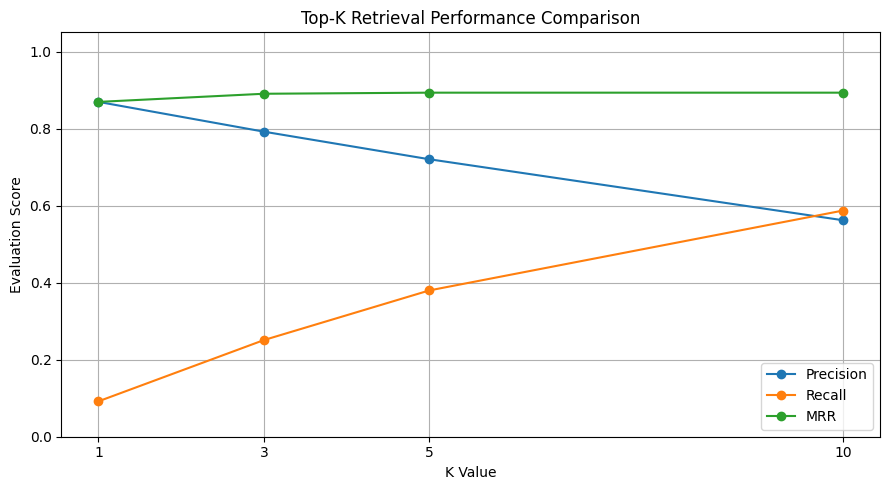

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    summary["K"], summary["Precision"],
    marker="o", label="Precision"
)

plt.plot(
    summary["K"], summary["Recall"],
    marker="o", label="Recall"
)

plt.plot(
    summary["K"], summary["MRR"],
    marker="o", label="MRR"
)

plt.title("Top-K Retrieval Performance Comparison")
plt.xlabel("K Value")
plt.ylabel("Evaluation Score")
plt.xticks([1, 3, 5, 10])
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

**K Selection:** We evaluated K values of 1, 3, 5 and 10 using Precision@K, Recall@K and MRR. K = 5 is a provisional choice because it provides a balance between precision and recall while maintaining a high MRR.

## Visualization branch Using PCA 2D vs UMap 2D

In [64]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Fit PCA using medical record embeddings only
pca_2d = PCA(n_components=2)

record_pca_2d = pca_2d.fit_transform(record_embeddings)

# Transform queries using the same PCA model
query_pca_2d = pca_2d.transform(query_embeddings)

print("Record PCA Shape:", record_pca_2d.shape)
print("Query PCA Shape:", query_pca_2d.shape)
print("Explained Variance:", pca_2d.explained_variance_ratio_.sum())

Record PCA Shape: (289, 2)
Query PCA Shape: (57, 2)
Explained Variance: 0.13505605


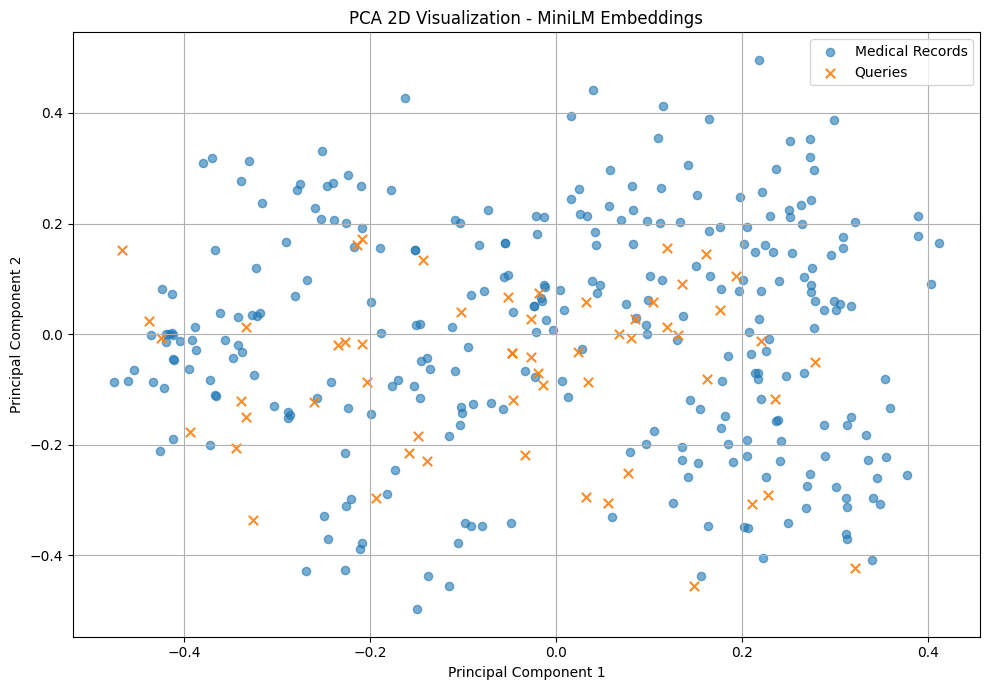

In [65]:
plt.figure(figsize=(10, 7))

plt.scatter(
    record_pca_2d[:, 0],
    record_pca_2d[:, 1],
    label="Medical Records",
    alpha=0.6,
    s=35
)

plt.scatter(
    query_pca_2d[:, 0],
    query_pca_2d[:, 1],
    label="Queries",
    alpha=0.9,
    s=45,
    marker="x"
)

plt.title("PCA 2D Visualization - MiniLM Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [66]:
%pip install umap-learn

In [67]:
import umap

# Fit UMAP using medical record embeddings
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

record_umap_2d = umap_model.fit_transform(record_embeddings)

# Transform queries using the same fitted UMAP model
query_umap_2d = umap_model.transform(query_embeddings)

print("Record UMAP Shape:", record_umap_2d.shape)
print("Query UMAP Shape:", query_umap_2d.shape)

Record UMAP Shape: (289, 2)
Query UMAP Shape: (57, 2)


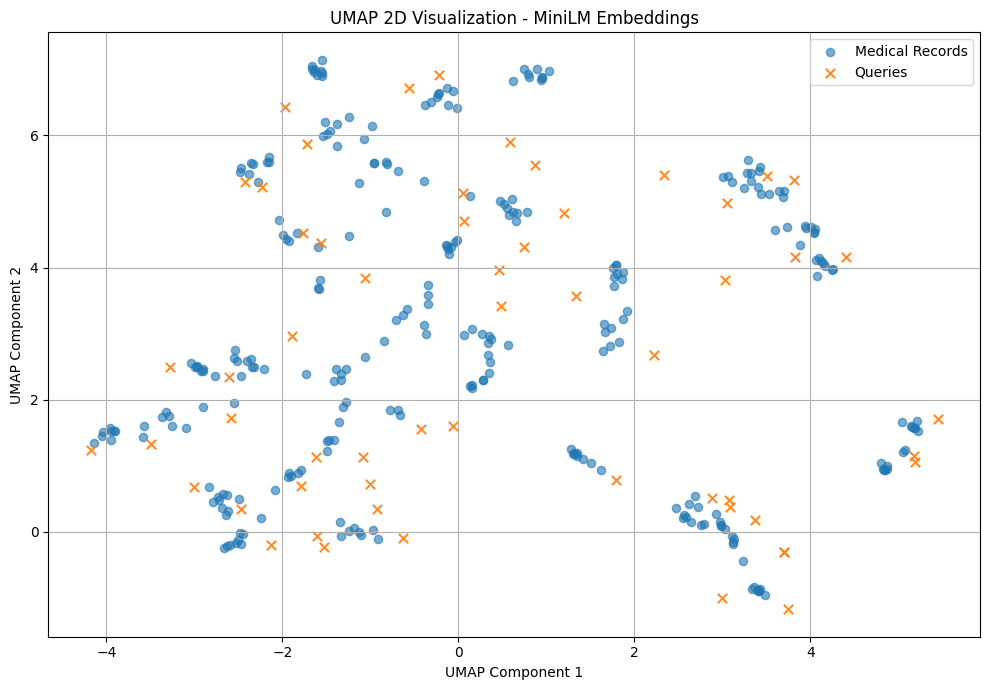

In [68]:
plt.figure(figsize=(10, 7))

plt.scatter(
    record_umap_2d[:, 0],
    record_umap_2d[:, 1],
    label="Medical Records",
    alpha=0.6,
    s=35
)

plt.scatter(
    query_umap_2d[:, 0],
    query_umap_2d[:, 1],
    label="Queries",
    alpha=0.9,
    s=45,
    marker="x"
)

plt.title("UMAP 2D Visualization - MiniLM Embeddings")
plt.xlabel("UMAP Component 1")
plt.ylabel("UMAP Component 2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Combine and Compare Retrieval Experiments.

In [69]:
# Combine all MiniLM evaluation results
minilm_comparison = evaluation_df.copy()

# Add model name
minilm_comparison.insert(0, "Model", "MiniLM")

# Sort results for easy comparison
minilm_comparison = minilm_comparison.sort_values(
    by=["K", "MRR"],
    ascending=[True, False]
).reset_index(drop=True)

display(minilm_comparison.round(4))

,Model,Experiment,K,Precision,Recall,MRR
0,MiniLM,Cosine_Native_384D,1,0.8947,0.0948,0.8947
1,MiniLM,Dot_Product_Native_384D,1,0.8947,0.0948,0.8947
2,MiniLM,Normalized_Dot_Product_Native_384D,1,0.8947,0.0948,0.8947
3,MiniLM,Cosine_PCA_128D,1,0.8772,0.0928,0.8772
4,MiniLM,Normalized_Dot_Product_PCA_128D,1,0.8772,0.0928,0.8772
5,MiniLM,Dot_Product_PCA_128D,1,0.8596,0.0906,0.8596
6,MiniLM,Cosine_PCA_64D,1,0.8421,0.0891,0.8421
7,MiniLM,Dot_Product_PCA_64D,1,0.8421,0.0889,0.8421
8,MiniLM,Normalized_Dot_Product_PCA_64D,1,0.8421,0.0891,0.8421
9,MiniLM,Cosine_Native_384D,3,0.8012,0.2540,0.9123


In [70]:
best_experiments = (
    minilm_comparison
    .loc[
        minilm_comparison.groupby("K")["MRR"].idxmax(),
        ["Model", "Experiment", "K", "Precision", "Recall", "MRR"]
    ]
    .reset_index(drop=True)
)

display(best_experiments.round(4))

,Model,Experiment,K,Precision,Recall,MRR
0,MiniLM,Cosine_Native_384D,1,0.8947,0.0948,0.8947
1,MiniLM,Cosine_Native_384D,3,0.8012,0.2540,0.9123
2,MiniLM,Cosine_Native_384D,5,0.7228,0.3799,0.9123
3,MiniLM,Cosine_Native_384D,10,0.5632,0.5885,0.9123


## MPNet - Tokenization and Embedding

In [72]:
# ==========================================
# MPNet - Tokenization and Embedding
# ==========================================

record_texts = df1["note_text"].tolist()
query_texts = df2["query_text"].tolist()

model = models["MPNet"]

mpnet_record_embeddings = model.encode(
    record_texts,
    show_progress_bar=True,
    convert_to_numpy=True
)

mpnet_query_embeddings = model.encode(
    query_texts,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("MPNet Embedding Completed!")
print("Record Embeddings Shape:", mpnet_record_embeddings.shape)
print("Query Embeddings Shape:", mpnet_query_embeddings.shape)

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

MPNet Embedding Completed!
Record Embeddings Shape: (289, 768)
Query Embeddings Shape: (57, 768)


In [75]:
# ==========================================
# DIMENSIONALITY EXPERIMENTS
# ==========================================

mpnet_dimensionality_results = {
    f"Native_{mpnet_record_embeddings.shape[1]}D": {
        "records": mpnet_record_embeddings,
        "queries": mpnet_query_embeddings
    }
}

# PCA experiments
mpnet_pca_models = {}

for dimensions in [128, 64]:

    pca = PCA(n_components=dimensions)

    record_reduced = pca.fit_transform(mpnet_record_embeddings)
    query_reduced = pca.transform(mpnet_query_embeddings)

    mpnet_dimensionality_results[f"PCA_{dimensions}D"] = {
        "records": record_reduced,
        "queries": query_reduced
    }

    mpnet_pca_models[dimensions] = pca

    print(f"\nMPNet PCA {dimensions}D Completed")
    print("Record Shape:", record_reduced.shape)
    print("Query Shape:", query_reduced.shape)
    print("Explained Variance:", pca.explained_variance_ratio_.sum())

print("\nAll MPNet Dimensionality Experiments Completed!")


MPNet PCA 128D Completed
Record Shape: (289, 128)
Query Shape: (57, 128)
Explained Variance: 0.9689853

MPNet PCA 64D Completed
Record Shape: (289, 64)
Query Shape: (57, 64)
Explained Variance: 0.8804854

All MPNet Dimensionality Experiments Completed!


In [76]:
# ==========================================
# MPNet: SIMILARITY EXPERIMENTS
# ==========================================

import time
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
from sklearn.preprocessing import normalize

mpnet_cosine_results = {}
mpnet_dot_product_results = {}
mpnet_normalized_dot_results = {}

mpnet_similarity_results = {
    "Cosine": mpnet_cosine_results,
    "Dot_Product": mpnet_dot_product_results,
    "Normalized_Dot_Product": mpnet_normalized_dot_results
}

# Calculate all three similarity methods
for name, data in mpnet_dimensionality_results.items():

    # Cosine Similarity
    mpnet_cosine = cosine_similarity(
        data["queries"],
        data["records"]
    )
    mpnet_cosine_results[name] = mpnet_cosine

    # Unnormalized Dot Product
    mpnet_dot = linear_kernel(
        data["queries"],
        data["records"]
    )
    mpnet_dot_product_results[name] = mpnet_dot

    # Normalized Dot Product
    records_norm = normalize(data["records"], norm="l2")
    queries_norm = normalize(data["queries"], norm="l2")

    mpnet_normalized_dot = linear_kernel(
        queries_norm,
        records_norm
    )
    mpnet_normalized_dot_results[name] = mpnet_normalized_dot

    print(f"\n{name}")
    print("Cosine Shape:", mpnet_cosine.shape)
    print("Dot Product Shape:", mpnet_dot.shape)
    print("Normalized Dot Shape:", mpnet_normalized_dot.shape)

print("\nAll MPNet Similarity Experiments Completed!")


# ==========================================
# RANK RECORDS BY SIMILARITY
# ==========================================

mpnet_ranked_results = {}

for method, experiments in mpnet_similarity_results.items():

    for dimension, similarity_matrix in experiments.items():

        ranked_indices = np.argsort(-similarity_matrix, axis=1)

        mpnet_ranked_results[f"{method}_{dimension}"] = ranked_indices

        print(f"{method}_{dimension}: Ranking Completed")


# ==========================================
# TOP-5 RETRIEVAL
# ==========================================

K = 5

mpnet_top5_results = {}

for experiment, rankings in mpnet_ranked_results.items():

    mpnet_top5_results[experiment] = rankings[:, :K]

print("\nMPNet Top-5 Retrieval Completed!")


# ==========================================
# EVALUATION
# ==========================================

record_ids = df1["record_id"].tolist()

mpnet_evaluation_results = []
mpnet_latency_results = []
mpnet_storage_results = []

for experiment, rankings in mpnet_ranked_results.items():

    precisions = []
    recalls = []
    reciprocal_ranks_top5 = []
    reciprocal_ranks_full = []

    for query_index, indices in enumerate(rankings):

        relevant_ids = df2["relevant_record_ids"].iloc[query_index]

        # Exclude queries without relevance labels
        if not isinstance(relevant_ids, list) or len(relevant_ids) == 0:
            continue

        relevant_ids = set(relevant_ids)

        retrieved_ids = [record_ids[index] for index in indices]
        top5_ids = retrieved_ids[:K]

        relevant_found = [
            rid for rid in top5_ids if rid in relevant_ids
        ]

        # Precision@5
        precision = len(relevant_found) / K

        # Recall@5
        recall = len(relevant_found) / len(relevant_ids)

        # MRR@5
        reciprocal_rank_top5 = 0

        for rank, rid in enumerate(top5_ids, start=1):
            if rid in relevant_ids:
                reciprocal_rank_top5 = 1 / rank
                break

        # Full MRR
        reciprocal_rank_full = 0

        for rank, rid in enumerate(retrieved_ids, start=1):
            if rid in relevant_ids:
                reciprocal_rank_full = 1 / rank
                break

        precisions.append(precision)
        recalls.append(recall)
        reciprocal_ranks_top5.append(reciprocal_rank_top5)
        reciprocal_ranks_full.append(reciprocal_rank_full)

    mpnet_evaluation_results.append({
        "Model": "MPNet",
        "Experiment": experiment,
        "K": K,
        "Precision@5": np.mean(precisions),
        "Recall@5": np.mean(recalls),
        "MRR@5": np.mean(reciprocal_ranks_top5),
        "Full_MRR": np.mean(reciprocal_ranks_full),
        "Evaluated_Queries": len(precisions)
    })


# ==========================================
# LATENCY AND STORAGE
# ==========================================

for experiment, data in mpnet_dimensionality_results.items():

    # Storage of record and query embeddings
    total_storage = (
        data["records"].nbytes + data["queries"].nbytes
    ) / (1024 ** 2)

    mpnet_storage_results.append({
        "Model": "MPNet",
        "Dimension": experiment,
        "Storage_MB": total_storage
    })


# Measure similarity + ranking latency for each method
for method, experiments in mpnet_similarity_results.items():

    for dimension, data in mpnet_dimensionality_results.items():

        start_time = time.perf_counter()

        similarity_matrix = experiments[dimension]
        rankings = np.argsort(-similarity_matrix, axis=1)
        top5 = rankings[:, :K]

        elapsed_time = time.perf_counter() - start_time

        mpnet_latency_results.append({
            "Model": "MPNet",
            "Experiment": dimension,
            "Similarity": method,
            "Average_Query_Latency_ms":
                (elapsed_time / len(query_texts)) * 1000
        })


# ==========================================
# DISPLAY RESULTS
# ==========================================

mpnet_evaluation_df = pd.DataFrame(mpnet_evaluation_results)
mpnet_latency_df = pd.DataFrame(mpnet_latency_results)
mpnet_storage_df = pd.DataFrame(mpnet_storage_results)

print("\nMPNet Evaluation Results")
display(mpnet_evaluation_df.round(4))

print("\nMPNet Latency Results")
display(mpnet_latency_df.round(4))

print("\nMPNet Storage Results")
display(mpnet_storage_df.round(4))


Native_768D
Cosine Shape: (57, 289)
Dot Product Shape: (57, 289)
Normalized Dot Shape: (57, 289)

PCA_128D
Cosine Shape: (57, 289)
Dot Product Shape: (57, 289)
Normalized Dot Shape: (57, 289)

PCA_64D
Cosine Shape: (57, 289)
Dot Product Shape: (57, 289)
Normalized Dot Shape: (57, 289)

All MPNet Similarity Experiments Completed!
Cosine_Native_768D: Ranking Completed
Cosine_PCA_128D: Ranking Completed
Cosine_PCA_64D: Ranking Completed
Dot_Product_Native_768D: Ranking Completed
Dot_Product_PCA_128D: Ranking Completed
Dot_Product_PCA_64D: Ranking Completed
Normalized_Dot_Product_Native_768D: Ranking Completed
Normalized_Dot_Product_PCA_128D: Ranking Completed
Normalized_Dot_Product_PCA_64D: Ranking Completed

MPNet Top-5 Retrieval Completed!

MPNet Evaluation Results


,Model,Experiment,K,Precision@5,Recall@5,MRR@5,Full_MRR,Evaluated_Queries
0,MPNet,Cosine_Native_768D,5,0.7778,0.4140,0.9506,0.9523,54
1,MPNet,Cosine_PCA_128D,5,0.7667,0.4088,0.8935,0.8951,54
2,MPNet,Cosine_PCA_64D,5,0.7407,0.3935,0.8549,0.8587,54
3,MPNet,Dot_Product_Native_768D,5,0.7778,0.4140,0.9506,0.9523,54
4,MPNet,Dot_Product_PCA_128D,5,0.7185,0.3814,0.8556,0.8568,54
5,MPNet,Dot_Product_PCA_64D,5,0.6963,0.3704,0.7877,0.7982,54
6,MPNet,Normalized_Dot_Product_Native_768D,5,0.7778,0.4140,0.9506,0.9523,54
7,MPNet,Normalized_Dot_Product_PCA_128D,5,0.7667,0.4088,0.8935,0.8951,54
8,MPNet,Normalized_Dot_Product_PCA_64D,5,0.7407,0.3935,0.8549,0.8587,54



MPNet Latency Results


,Model,Experiment,Similarity,Average_Query_Latency_ms
0,MPNet,Native_768D,Cosine,0.0147
1,MPNet,PCA_128D,Cosine,0.0859
2,MPNet,PCA_64D,Cosine,0.0143
3,MPNet,Native_768D,Dot_Product,0.0132
4,MPNet,PCA_128D,Dot_Product,0.0887
5,MPNet,PCA_64D,Dot_Product,0.0165
6,MPNet,Native_768D,Normalized_Dot_Product,0.0853
7,MPNet,PCA_128D,Normalized_Dot_Product,0.0150
8,MPNet,PCA_64D,Normalized_Dot_Product,0.1218



MPNet Storage Results


,Model,Dimension,Storage_MB
0,MPNet,Native_768D,1.0137
1,MPNet,PCA_128D,0.1689
2,MPNet,PCA_64D,0.0845


## S-PubMedBERT: TOKENIZATION AND EMBEDDING

In [77]:
# ==========================================
# S-PubMedBERT: TOKENIZATION AND EMBEDDING
# ==========================================

import numpy as np
from sklearn.decomposition import PCA

# Select S-PubMedBERT model
spubmed_model = models["S-PubMedBERT"]

# Prepare record and query text
record_texts = df1["note_text"].tolist()
query_texts = df2["query_text"].tolist()

# Generate record embeddings
spubmed_record_embeddings = spubmed_model.encode(
    record_texts,
    show_progress_bar=True,
    convert_to_numpy=True
)

# Generate query embeddings
spubmed_query_embeddings = spubmed_model.encode(
    query_texts,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("S-PubMedBERT Embedding Completed!")
print("Record Embeddings Shape:", spubmed_record_embeddings.shape)
print("Query Embeddings Shape:", spubmed_query_embeddings.shape)


# ==========================================
# DIMENSIONALITY EXPERIMENTS
# ==========================================

spubmed_dimensionality_results = {
    f"Native_{spubmed_record_embeddings.shape[1]}D": {
        "records": spubmed_record_embeddings,
        "queries": spubmed_query_embeddings
    }
}

spubmed_pca_models = {}

# PCA experiments
for dimensions in [128, 64]:

    pca = PCA(n_components=dimensions)

    record_reduced = pca.fit_transform(spubmed_record_embeddings)
    query_reduced = pca.transform(spubmed_query_embeddings)

    spubmed_dimensionality_results[f"PCA_{dimensions}D"] = {
        "records": record_reduced,
        "queries": query_reduced
    }

    spubmed_pca_models[dimensions] = pca

    print(f"\nS-PubMedBERT PCA {dimensions}D Completed")
    print("Record Shape:", record_reduced.shape)
    print("Query Shape:", query_reduced.shape)
    print("Explained Variance:", pca.explained_variance_ratio_.sum())

print("\nAll S-PubMedBERT Dimensionality Experiments Completed!")

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

S-PubMedBERT Embedding Completed!
Record Embeddings Shape: (289, 768)
Query Embeddings Shape: (57, 768)

S-PubMedBERT PCA 128D Completed
Record Shape: (289, 128)
Query Shape: (57, 128)
Explained Variance: 0.97608066

S-PubMedBERT PCA 64D Completed
Record Shape: (289, 64)
Query Shape: (57, 64)
Explained Variance: 0.8787072

All S-PubMedBERT Dimensionality Experiments Completed!


In [78]:
# ==========================================
# S-PubMedBERT: SIMILARITY EXPERIMENTS
# ==========================================

import time
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
from sklearn.preprocessing import normalize

spubmed_cosine_results = {}
spubmed_dot_product_results = {}
spubmed_normalized_dot_results = {}

spubmed_similarity_results = {
    "Cosine": spubmed_cosine_results,
    "Dot_Product": spubmed_dot_product_results,
    "Normalized_Dot_Product": spubmed_normalized_dot_results
}

# Calculate all three similarity methods
for name, data in spubmed_dimensionality_results.items():

    # Cosine Similarity
    spubmed_cosine = cosine_similarity(
        data["queries"],
        data["records"]
    )
    spubmed_cosine_results[name] = spubmed_cosine

    # Unnormalized Dot Product
    spubmed_dot = linear_kernel(
        data["queries"],
        data["records"]
    )
    spubmed_dot_product_results[name] = spubmed_dot

    # Normalized Dot Product
    records_norm = normalize(data["records"], norm="l2")
    queries_norm = normalize(data["queries"], norm="l2")

    spubmed_normalized_dot = linear_kernel(
        queries_norm,
        records_norm
    )
    spubmed_normalized_dot_results[name] = spubmed_normalized_dot

    print(f"\n{name}")
    print("Cosine Shape:", spubmed_cosine.shape)
    print("Dot Product Shape:", spubmed_dot.shape)
    print("Normalized Dot Shape:", spubmed_normalized_dot.shape)

print("\nAll S-PubMedBERT Similarity Experiments Completed!")


# ==========================================
# RANK RECORDS BY SIMILARITY
# ==========================================

spubmed_ranked_results = {}

for method, experiments in spubmed_similarity_results.items():

    for dimension, similarity_matrix in experiments.items():

        ranked_indices = np.argsort(-similarity_matrix, axis=1)

        spubmed_ranked_results[f"{method}_{dimension}"] = ranked_indices

        print(f"{method}_{dimension}: Ranking Completed")


# ==========================================
# TOP-5 RETRIEVAL
# ==========================================

K = 5

spubmed_top5_results = {}

for experiment, rankings in spubmed_ranked_results.items():

    spubmed_top5_results[experiment] = rankings[:, :K]

print("\nS-PubMedBERT Top-5 Retrieval Completed!")


# ==========================================
# EVALUATION
# ==========================================

record_ids = df1["record_id"].tolist()

spubmed_evaluation_results = []
spubmed_latency_results = []
spubmed_storage_results = []

for experiment, rankings in spubmed_ranked_results.items():

    precisions = []
    recalls = []
    reciprocal_ranks_top5 = []
    reciprocal_ranks_full = []

    for query_index, indices in enumerate(rankings):

        relevant_ids = df2["relevant_record_ids"].iloc[query_index]

        # Exclude queries without relevance labels
        if not isinstance(relevant_ids, list) or len(relevant_ids) == 0:
            continue

        relevant_ids = set(relevant_ids)

        retrieved_ids = [record_ids[index] for index in indices]
        top5_ids = retrieved_ids[:K]

        relevant_found = [
            rid for rid in top5_ids if rid in relevant_ids
        ]

        # Precision@5
        precision = len(relevant_found) / K

        # Recall@5
        recall = len(relevant_found) / len(relevant_ids)

        # MRR@5
        reciprocal_rank_top5 = 0

        for rank, rid in enumerate(top5_ids, start=1):
            if rid in relevant_ids:
                reciprocal_rank_top5 = 1 / rank
                break

        # Full MRR
        reciprocal_rank_full = 0

        for rank, rid in enumerate(retrieved_ids, start=1):
            if rid in relevant_ids:
                reciprocal_rank_full = 1 / rank
                break

        precisions.append(precision)
        recalls.append(recall)
        reciprocal_ranks_top5.append(reciprocal_rank_top5)
        reciprocal_ranks_full.append(reciprocal_rank_full)

    spubmed_evaluation_results.append({
        "Model": "S-PubMedBERT",
        "Experiment": experiment,
        "K": K,
        "Precision@5": np.mean(precisions),
        "Recall@5": np.mean(recalls),
        "MRR@5": np.mean(reciprocal_ranks_top5),
        "Full_MRR": np.mean(reciprocal_ranks_full),
        "Evaluated_Queries": len(precisions)
    })


# ==========================================
# LATENCY AND STORAGE
# ==========================================

for experiment, data in spubmed_dimensionality_results.items():

    # Storage of record and query embeddings
    total_storage = (
        data["records"].nbytes + data["queries"].nbytes
    ) / (1024 ** 2)

    spubmed_storage_results.append({
        "Model": "S-PubMedBERT",
        "Dimension": experiment,
        "Storage_MB": total_storage
    })


# Measure similarity + ranking latency for each method
for method, experiments in spubmed_similarity_results.items():

    for dimension, data in spubmed_dimensionality_results.items():

        start_time = time.perf_counter()

        similarity_matrix = experiments[dimension]
        rankings = np.argsort(-similarity_matrix, axis=1)
        top5 = rankings[:, :K]

        elapsed_time = time.perf_counter() - start_time

        spubmed_latency_results.append({
            "Model": "S-PubMedBERT",
            "Experiment": dimension,
            "Similarity": method,
            "Average_Query_Latency_ms":
                (elapsed_time / len(query_texts)) * 1000
        })


# ==========================================
# DISPLAY RESULTS
# ==========================================

spubmed_evaluation_df = pd.DataFrame(spubmed_evaluation_results)
spubmed_latency_df = pd.DataFrame(spubmed_latency_results)
spubmed_storage_df = pd.DataFrame(spubmed_storage_results)

print("\nS-PubMedBERT Evaluation Results")
display(spubmed_evaluation_df.round(4))

print("\nS-PubMedBERT Latency Results")
display(spubmed_latency_df.round(4))

print("\nS-PubMedBERT Storage Results")
display(spubmed_storage_df.round(4))


Native_768D
Cosine Shape: (57, 289)
Dot Product Shape: (57, 289)
Normalized Dot Shape: (57, 289)

PCA_128D
Cosine Shape: (57, 289)
Dot Product Shape: (57, 289)
Normalized Dot Shape: (57, 289)

PCA_64D
Cosine Shape: (57, 289)
Dot Product Shape: (57, 289)
Normalized Dot Shape: (57, 289)

All S-PubMedBERT Similarity Experiments Completed!
Cosine_Native_768D: Ranking Completed
Cosine_PCA_128D: Ranking Completed
Cosine_PCA_64D: Ranking Completed
Dot_Product_Native_768D: Ranking Completed
Dot_Product_PCA_128D: Ranking Completed
Dot_Product_PCA_64D: Ranking Completed
Normalized_Dot_Product_Native_768D: Ranking Completed
Normalized_Dot_Product_PCA_128D: Ranking Completed
Normalized_Dot_Product_PCA_64D: Ranking Completed

S-PubMedBERT Top-5 Retrieval Completed!

S-PubMedBERT Evaluation Results


,Model,Experiment,K,Precision@5,Recall@5,MRR@5,Full_MRR,Evaluated_Queries
0,S-PubMedBERT,Cosine_Native_768D,5,0.7296,0.3870,0.9506,0.9506,54
1,S-PubMedBERT,Cosine_PCA_128D,5,0.7074,0.3767,0.9228,0.9274,54
2,S-PubMedBERT,Cosine_PCA_64D,5,0.7259,0.3863,0.9244,0.9258,54
3,S-PubMedBERT,Dot_Product_Native_768D,5,0.7259,0.3851,0.9244,0.9270,54
4,S-PubMedBERT,Dot_Product_PCA_128D,5,0.6667,0.3539,0.8781,0.8827,54
5,S-PubMedBERT,Dot_Product_PCA_64D,5,0.6667,0.3528,0.8664,0.8710,54
6,S-PubMedBERT,Normalized_Dot_Product_Native_768D,5,0.7296,0.3870,0.9506,0.9506,54
7,S-PubMedBERT,Normalized_Dot_Product_PCA_128D,5,0.7074,0.3767,0.9228,0.9274,54
8,S-PubMedBERT,Normalized_Dot_Product_PCA_64D,5,0.7259,0.3863,0.9244,0.9258,54



S-PubMedBERT Latency Results


,Model,Experiment,Similarity,Average_Query_Latency_ms
0,S-PubMedBERT,Native_768D,Cosine,0.0161
1,S-PubMedBERT,PCA_128D,Cosine,0.0147
2,S-PubMedBERT,PCA_64D,Cosine,0.0134
3,S-PubMedBERT,Native_768D,Dot_Product,0.0168
4,S-PubMedBERT,PCA_128D,Dot_Product,0.0128
5,S-PubMedBERT,PCA_64D,Dot_Product,0.0139
6,S-PubMedBERT,Native_768D,Normalized_Dot_Product,0.0144
7,S-PubMedBERT,PCA_128D,Normalized_Dot_Product,0.0135
8,S-PubMedBERT,PCA_64D,Normalized_Dot_Product,0.0134



S-PubMedBERT Storage Results


,Model,Dimension,Storage_MB
0,S-PubMedBERT,Native_768D,1.0137
1,S-PubMedBERT,PCA_128D,0.1689
2,S-PubMedBERT,PCA_64D,0.0845


In [79]:
# ==========================================
# STANDARDIZED EVALUATION FOR ALL 3 MODELS
# ==========================================

import numpy as np
import pandas as pd

record_ids = df1["record_id"].tolist()

# Store all model rankings in one dictionary
all_ranked_results = {
    "MiniLM": ranked_results,
    "MPNet": mpnet_ranked_results,
    "S-PubMedBERT": spubmed_ranked_results
}

all_evaluation_results = []

K = 5

for model_name, model_rankings in all_ranked_results.items():

    for experiment, rankings in model_rankings.items():

        precisions = []
        recalls = []
        reciprocal_ranks_top5 = []
        reciprocal_ranks_full = []

        for query_index, indices in enumerate(rankings):

            relevant_ids = df2["relevant_record_ids"].iloc[query_index]

            # Skip queries without valid relevance labels
            if not isinstance(relevant_ids, list) or len(relevant_ids) == 0:
                continue

            relevant_ids = set(relevant_ids)

            retrieved_ids = [
                record_ids[index] for index in indices
            ]

            top5_ids = retrieved_ids[:K]

            relevant_found = [
                rid for rid in top5_ids if rid in relevant_ids
            ]

            # Precision@5
            precision = len(relevant_found) / K

            # Recall@5
            recall = len(relevant_found) / len(relevant_ids)

            # MRR@5
            reciprocal_rank_top5 = 0

            for rank, rid in enumerate(top5_ids, start=1):
                if rid in relevant_ids:
                    reciprocal_rank_top5 = 1 / rank
                    break

            # Full MRR
            reciprocal_rank_full = 0

            for rank, rid in enumerate(retrieved_ids, start=1):
                if rid in relevant_ids:
                    reciprocal_rank_full = 1 / rank
                    break

            precisions.append(precision)
            recalls.append(recall)
            reciprocal_ranks_top5.append(reciprocal_rank_top5)
            reciprocal_ranks_full.append(reciprocal_rank_full)

        all_evaluation_results.append({
            "Model": model_name,
            "Experiment": experiment,
            "K": K,
            "Precision@5": np.mean(precisions),
            "Recall@5": np.mean(recalls),
            "MRR@5": np.mean(reciprocal_ranks_top5),
            "Full_MRR": np.mean(reciprocal_ranks_full),
            "Evaluated_Queries": len(precisions)
        })


# Create final evaluation DataFrame
all_evaluation_df = pd.DataFrame(all_evaluation_results)

all_evaluation_df = all_evaluation_df.sort_values(
    by="MRR@5",
    ascending=False
).reset_index(drop=True)

print("Standardized Evaluation Completed!")

display(all_evaluation_df.round(4))

Standardized Evaluation Completed!


,Model,Experiment,K,Precision@5,Recall@5,MRR@5,Full_MRR,Evaluated_Queries
0,MiniLM,Cosine_Native_384D,5,0.7630,0.4010,0.9630,0.9637,54
1,MiniLM,Normalized_Dot_Product_Native_384D,5,0.7630,0.4010,0.9630,0.9637,54
2,MiniLM,Dot_Product_Native_384D,5,0.7630,0.4010,0.9630,0.9637,54
3,MiniLM,Normalized_Dot_Product_PCA_128D,5,0.7630,0.4028,0.9506,0.9516,54
4,MiniLM,Cosine_PCA_128D,5,0.7630,0.4028,0.9506,0.9516,54
5,MPNet,Cosine_Native_768D,5,0.7778,0.4140,0.9506,0.9523,54
6,MPNet,Dot_Product_Native_768D,5,0.7778,0.4140,0.9506,0.9523,54
7,S-PubMedBERT,Normalized_Dot_Product_Native_768D,5,0.7296,0.3870,0.9506,0.9506,54
8,S-PubMedBERT,Cosine_Native_768D,5,0.7296,0.3870,0.9506,0.9506,54
9,MPNet,Normalized_Dot_Product_Native_768D,5,0.7778,0.4140,0.9506,0.9523,54


In [82]:
# ==========================================
# CORRECTED LATENCY AND STORAGE COMPARISON
# ==========================================

import time
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
from sklearn.preprocessing import normalize

# Original embeddings for each model
raw_embeddings = {
    "MiniLM": record_embeddings,
    "MPNet": mpnet_record_embeddings,
    "S-PubMedBERT": spubmed_record_embeddings
}

all_models_data = {
    "MiniLM": {
        "model": models["MiniLM"],
        "dimensions": dimensionality_results
    },
    "MPNet": {
        "model": models["MPNet"],
        "dimensions": mpnet_dimensionality_results
    },
    "S-PubMedBERT": {
        "model": models["S-PubMedBERT"],
        "dimensions": spubmed_dimensionality_results
    }
}

latency_results = []
storage_results = []

for model_name, model_data in all_models_data.items():

    model = model_data["model"]
    dimension_data = model_data["dimensions"]

    original_records = raw_embeddings[model_name]

    # Fit PCA using original corpus embeddings only
    pca_models = {}

    for dimensions in [128, 64]:

        pca = PCA(n_components=dimensions)
        pca.fit(original_records)

        pca_models[dimensions] = pca

    # Encode queries and measure encoding time
    encoded_queries = []
    query_encoding_times = []

    for query_text in query_texts:

        start = time.perf_counter()

        query_vector = model.encode(
            [query_text],
            convert_to_numpy=True,
            show_progress_bar=False
        )

        query_encoding_times.append(
            time.perf_counter() - start
        )

        encoded_queries.append(query_vector)

    # Test every dimension
    for dimension_name, data in dimension_data.items():

        records = data["records"]

        if records.shape[1] == original_records.shape[1]:

            pca = None

        else:

            pca = pca_models[records.shape[1]]

        # Storage
        storage_results.append({
            "Model": model_name,
            "Dimension": dimension_name,
            "Corpus_Storage_MB":
                records.nbytes / (1024 ** 2),
            "Query_Storage_MB":
                data["queries"].nbytes / (1024 ** 2)
        })

        # Similarity experiments
        for method in [
            "Cosine",
            "Dot_Product",
            "Normalized_Dot_Product"
        ]:

            total_times = []

            for query_index, original_query in enumerate(encoded_queries):

                start = time.perf_counter()

                query_vector = original_query.copy()

                # Transform query if PCA is used
                if pca is not None:
                    query_vector = pca.transform(query_vector)

                # Safety check: both vectors must have equal dimensions
                assert query_vector.shape[1] == records.shape[1], (
                    f"Dimension mismatch: {model_name}, "
                    f"{dimension_name}"
                )

                # Similarity calculation
                if method == "Cosine":

                    scores = cosine_similarity(
                        query_vector, records
                    )[0]

                elif method == "Dot_Product":

                    scores = linear_kernel(
                        query_vector, records
                    )[0]

                else:

                    scores = linear_kernel(
                        normalize(query_vector),
                        normalize(records)
                    )[0]

                # Ranking and Top-5
                ranking = np.argsort(-scores)
                top5 = ranking[:5]

                retrieval_time = time.perf_counter() - start

                total_time = (
                    query_encoding_times[query_index]
                    + retrieval_time
                )

                total_times.append(total_time * 1000)

            latency_results.append({
                "Model": model_name,
                "Dimension": dimension_name,
                "Similarity": method,
                "Median_Query_Latency_ms":
                    np.median(total_times)
            })


latency_df = pd.DataFrame(latency_results)
storage_df = pd.DataFrame(storage_results)

print("Latency Comparison")
display(latency_df.round(4))

print("Storage Comparison")
display(storage_df.round(4))

print("All dimensionality checks passed!")

Latency Comparison


,Model,Dimension,Similarity,Median_Query_Latency_ms
0,MiniLM,Native_384D,Cosine,42.2643
1,MiniLM,Native_384D,Dot_Product,41.0733
2,MiniLM,Native_384D,Normalized_Dot_Product,42.4196
3,MiniLM,PCA_128D,Cosine,41.8511
4,MiniLM,PCA_128D,Dot_Product,41.3367
5,MiniLM,PCA_128D,Normalized_Dot_Product,42.3526
6,MiniLM,PCA_64D,Cosine,42.6702
7,MiniLM,PCA_64D,Dot_Product,41.2995
8,MiniLM,PCA_64D,Normalized_Dot_Product,42.2699
9,MPNet,Native_768D,Cosine,209.1583


Storage Comparison


,Model,Dimension,Corpus_Storage_MB,Query_Storage_MB
0,MiniLM,Native_384D,0.4233,0.0835
1,MiniLM,PCA_128D,0.1411,0.0278
2,MiniLM,PCA_64D,0.0706,0.0139
3,MPNet,Native_768D,0.8467,0.1670
4,MPNet,PCA_128D,0.1411,0.0278
5,MPNet,PCA_64D,0.0706,0.0139
6,S-PubMedBERT,Native_768D,0.8467,0.1670
7,S-PubMedBERT,PCA_128D,0.1411,0.0278
8,S-PubMedBERT,PCA_64D,0.0706,0.0139


All dimensionality checks passed!


In [83]:

# ==========================================
# CELL 87: COMBINE RESULTS & COMPARE EXPERIMENTS
# Focus: 128D across all three models
# ==========================================

import pandas as pd

# Convert latency and storage results into DataFrames
latency_df = pd.DataFrame(latency_results)
storage_df = pd.DataFrame(storage_results)

# ------------------------------------------
# 1. Extract dimension and similarity method
# ------------------------------------------

def extract_dimension(experiment):
    if "PCA_128D" in experiment:
        return "PCA_128D"
    elif "PCA_64D" in experiment:
        return "PCA_64D"
    elif "Native" in experiment:
        return "Native"
    return "Unknown"


def extract_similarity(experiment):
    if experiment.startswith("Normalized_Dot_Product"):
        return "Normalized_Dot_Product"
    elif experiment.startswith("Dot_Product"):
        return "Dot_Product"
    elif experiment.startswith("Cosine"):
        return "Cosine"
    return "Unknown"


# ------------------------------------------
# 2. Prepare evaluation results
# ------------------------------------------

comparison_eval = all_evaluation_df.copy()

comparison_eval["Dimension"] = comparison_eval["Experiment"].apply(
    extract_dimension
)

comparison_eval["Similarity"] = comparison_eval["Experiment"].apply(
    extract_similarity
)

# Keep only 128D experiments
comparison_eval = comparison_eval[
    comparison_eval["Dimension"] == "PCA_128D"
].copy()


# ------------------------------------------
# 3. Prepare latency and storage results
# ------------------------------------------

# Keep only 128D experiments
latency_128 = latency_df[
    latency_df["Dimension"] == "PCA_128D"
].copy()

storage_128 = storage_df[
    storage_df["Dimension"] == "PCA_128D"
].copy()


# ------------------------------------------
# 4. Combine all three result tables
# ------------------------------------------

comparison_df = comparison_eval.merge(
    latency_128,
    on=["Model", "Dimension", "Similarity"],
    how="inner"
)

comparison_df = comparison_df.merge(
    storage_128[["Model", "Dimension", "Corpus_Storage_MB"]],
    on=["Model", "Dimension"],
    how="left"
)


# ------------------------------------------
# 5. Display final 128D comparison
# ------------------------------------------

comparison_df = comparison_df.sort_values(
    by="MRR@5",
    ascending=False
).reset_index(drop=True)

print("128D MODEL COMPARISON COMPLETED!")

display(comparison_df.round(4))


# ------------------------------------------
# 6. Best similarity configuration per model
# ------------------------------------------

best_per_model = (
    comparison_df.sort_values(
        by="MRR@5",
        ascending=False
    )
    .groupby("Model")
    .head(1)
    .sort_values(by="MRR@5", ascending=False)
    .reset_index(drop=True)
)

print("\nBEST 128D CONFIGURATION FOR EACH MODEL:")

display(
    best_per_model[
        [
            "Model",
            "Dimension",
            "Similarity",
            "Precision@5",
            "Recall@5",
            "MRR@5",
            "Median_Query_Latency_ms",
            "Corpus_Storage_MB"
        ]
    ].round(4)
)


128D MODEL COMPARISON COMPLETED!


,Model,Experiment,K,Precision@5,Recall@5,MRR@5,Full_MRR,Evaluated_Queries,Dimension,Similarity,Median_Query_Latency_ms,Corpus_Storage_MB
0,MiniLM,Normalized_Dot_Product_PCA_128D,5,0.7630,0.4028,0.9506,0.9516,54,PCA_128D,Normalized_Dot_Product,42.3526,0.1411
1,MiniLM,Cosine_PCA_128D,5,0.7630,0.4028,0.9506,0.9516,54,PCA_128D,Cosine,41.8511,0.1411
2,MiniLM,Dot_Product_PCA_128D,5,0.7444,0.3928,0.9398,0.9410,54,PCA_128D,Dot_Product,41.3367,0.1411
3,S-PubMedBERT,Normalized_Dot_Product_PCA_128D,5,0.7074,0.3767,0.9228,0.9274,54,PCA_128D,Normalized_Dot_Product,139.5072,0.1411
4,S-PubMedBERT,Cosine_PCA_128D,5,0.7074,0.3767,0.9228,0.9274,54,PCA_128D,Cosine,138.8546,0.1411
5,MPNet,Cosine_PCA_128D,5,0.7667,0.4088,0.8935,0.8951,54,PCA_128D,Cosine,209.2649,0.1411
6,MPNet,Normalized_Dot_Product_PCA_128D,5,0.7667,0.4088,0.8935,0.8951,54,PCA_128D,Normalized_Dot_Product,211.2344,0.1411
7,S-PubMedBERT,Dot_Product_PCA_128D,5,0.6667,0.3539,0.8781,0.8827,54,PCA_128D,Dot_Product,138.5065,0.1411
8,MPNet,Dot_Product_PCA_128D,5,0.7185,0.3814,0.8556,0.8568,54,PCA_128D,Dot_Product,208.0983,0.1411



BEST 128D CONFIGURATION FOR EACH MODEL:


,Model,Dimension,Similarity,Precision@5,Recall@5,MRR@5,Median_Query_Latency_ms,Corpus_Storage_MB
0,MiniLM,PCA_128D,Normalized_Dot_Product,0.7630,0.4028,0.9506,42.3526,0.1411
1,S-PubMedBERT,PCA_128D,Normalized_Dot_Product,0.7074,0.3767,0.9228,139.5072,0.1411
2,MPNet,PCA_128D,Cosine,0.7667,0.4088,0.8935,209.2649,0.1411


In [85]:

# ==========================================
# CELL 88: QUERY-WISE RETRIEVAL COMPARISON
# Selected Model: MiniLM
# Dimension: PCA 128D
# Similarity: Cosine
# Top-K: 5
# ==========================================

import pandas as pd

# Selected model's retrieval rankings
selected_rankings = ranked_results["Cosine_PCA_128D"]

query_comparison = []

for query_index, predicted_indices in enumerate(selected_rankings):

    # Get actual relevant MR IDs
    actual_relevant_ids = df2["relevant_record_ids"].iloc[query_index]

    # Skip queries without ground-truth relevance labels
    if not isinstance(actual_relevant_ids, list) or len(actual_relevant_ids) == 0:
        continue

    # Get predicted Top-5 MR IDs in similarity-ranking order
    predicted_top5_ids = [
        record_ids[index] for index in predicted_indices[:5]
    ]

    # Sort actual and predicted IDs in ascending order for display
    actual_relevant_ids_sorted = sorted(actual_relevant_ids)
    predicted_top5_ids_sorted = sorted(predicted_top5_ids)

    # Find relevant records retrieved by the model
    matched_ids = [
        rid for rid in predicted_top5_ids
        if rid in actual_relevant_ids
    ]

    query_comparison.append({

        "Query_ID": df2["query_id"].iloc[query_index],

        "Query_Text": df2["query_text"].iloc[query_index],

        "Actual_Relevant_MR_IDs": actual_relevant_ids_sorted,

        "Predicted_Top5_MR_IDs": predicted_top5_ids_sorted,

        "Predicted_Top5_Ranking_Order": predicted_top5_ids,

        "Relevant_Records_Found": sorted(matched_ids),

        "Success": len(matched_ids) > 0
    })


# Convert results into DataFrame
query_comparison_df = pd.DataFrame(query_comparison)


# ==========================================
# DISPLAY RESULTS
# ==========================================

print("QUERY-WISE RETRIEVAL COMPARISON COMPLETED!")

print("Total Evaluated Queries:", len(query_comparison_df))

print(
    "Successful Queries:",
    query_comparison_df["Success"].sum()
)

print(
    "Queries with No Relevant Record in Top-5:",
    (~query_comparison_df["Success"]).sum()
)

display(query_comparison_df)


QUERY-WISE RETRIEVAL COMPARISON COMPLETED!
Total Evaluated Queries: 54
Successful Queries: 53
Queries with No Relevant Record in Top-5: 1


,Query_ID,Query_Text,Actual_Relevant_MR_IDs,Predicted_Top5_MR_IDs,Predicted_Top5_Ranking_Order,Relevant_Records_Found,Success
0,Q001,"wheezing and tight chest, needing rescue inhal...","[MR0049, MR0079, MR0086, MR0105, MR0141, MR015...","[MR0049, MR0141, MR0149, MR0210, MR0235]","[MR0049, MR0235, MR0210, MR0141, MR0149]","[MR0049, MR0141, MR0210, MR0235]",True
1,Q002,fever with productive cough and lung infection...,"[MR0037, MR0047, MR0091, MR0132, MR0137, MR021...","[MR0132, MR0134, MR0137, MR0266, MR0282]","[MR0132, MR0266, MR0282, MR0137, MR0134]","[MR0132, MR0137, MR0282]",True
2,Q003,longtime smoker getting more breathless with m...,"[MR0075, MR0097, MR0109, MR0144, MR0149, MR015...","[MR0049, MR0075, MR0097, MR0149, MR0218]","[MR0149, MR0075, MR0097, MR0218, MR0049]","[MR0075, MR0097, MR0149, MR0218]",True
3,Q004,cold symptoms with stuffy nose and sore throat,"[MR0028, MR0068, MR0134, MR0165, MR0182, MR020...","[MR0134, MR0165, MR0206, MR0257, MR0266]","[MR0257, MR0134, MR0266, MR0206, MR0165]","[MR0134, MR0165, MR0206, MR0257, MR0266]",True
4,Q005,chest pressure spreading to the arm with sweating,"[MR0018, MR0021, MR0069, MR0098, MR0145, MR018...","[MR0127, MR0145, MR0181, MR0229, MR0291]","[MR0181, MR0229, MR0291, MR0127, MR0145]","[MR0145, MR0181, MR0229, MR0291]",True
5,Q006,follow-up visit for high blood pressure readings,"[MR0007, MR0011, MR0065, MR0126, MR0139, MR015...","[MR0011, MR0126, MR0139, MR0227, MR0261]","[MR0011, MR0261, MR0126, MR0227, MR0139]","[MR0011, MR0126, MR0139, MR0227, MR0261]",True
6,Q007,irregular heartbeat and palpitations,"[MR0013, MR0039, MR0085, MR0117, MR0171, MR021...","[MR0013, MR0039, MR0117, MR0171, MR0214]","[MR0039, MR0117, MR0171, MR0214, MR0013]","[MR0013, MR0039, MR0117, MR0171, MR0214]",True
7,Q008,leg swelling and trouble breathing when lying ...,"[MR0005, MR0030, MR0051, MR0053, MR0121, MR013...","[MR0121, MR0131, MR0138, MR0142, MR0149]","[MR0121, MR0138, MR0142, MR0131, MR0149]","[MR0121, MR0138]",True
8,Q009,neck pain and stiffness after being rear-ended,"[MR0006, MR0022, MR0034, MR0089, MR0114, MR016...","[MR0022, MR0114, MR0166, MR0184, MR0222]","[MR0022, MR0222, MR0166, MR0184, MR0114]","[MR0022, MR0114, MR0166, MR0184, MR0222]",True
9,Q010,lower back pain after lifting something heavy,"[MR0113, MR0136, MR0143, MR0147, MR0185, MR019...","[MR0113, MR0136, MR0143, MR0147, MR0262]","[MR0147, MR0262, MR0143, MR0136, MR0113]","[MR0113, MR0136, MR0143, MR0147, MR0262]",True


In [87]:

# ==========================================
# CELL 88: QUERY-WISE PREDICTION COMPARISON
# All 3 Models - PCA 128D - Cosine Similarity
# ==========================================

import pandas as pd

# Selected Top-5 rankings for all models
selected_model_rankings = {
    "MiniLM": ranked_results["Cosine_PCA_128D"],
    "MPNet": mpnet_ranked_results["Cosine_PCA_128D"],
    "S-PubMedBERT": spubmed_ranked_results["Cosine_PCA_128D"]
}

query_comparison = []

for query_index in range(len(df2)):

    # Get actual relevant MR IDs
    actual_relevant_ids = df2["relevant_record_ids"].iloc[query_index]

    # Skip queries without relevance labels
    if not isinstance(actual_relevant_ids, list) or len(actual_relevant_ids) == 0:
        continue

    # Prepare one row for each query
    result = {
        "Query": df2["query_text"].iloc[query_index],
        "Actual_Relevant_MR_IDs": sorted(actual_relevant_ids)
    }

    # Get predictions from each model
    for model_name, rankings in selected_model_rankings.items():

        predicted_indices = rankings[query_index]

        predicted_top5_ids = [
            record_ids[index] for index in predicted_indices[:5]
        ]

        # Sort predicted IDs in ascending order
        result[f"{model_name}_Predicted_MR_IDs"] = sorted(predicted_top5_ids)

    query_comparison.append(result)


# Create final comparison DataFrame
query_comparison_df = pd.DataFrame(query_comparison)

# Display only the first 10 queries
print("QUERY-WISE PREDICTION COMPARISON")
print("Total labelled queries:", len(query_comparison_df))

display(query_comparison_df.head(10))


QUERY-WISE PREDICTION COMPARISON
Total labelled queries: 54


,Query,Actual_Relevant_MR_IDs,MiniLM_Predicted_MR_IDs,MPNet_Predicted_MR_IDs,S-PubMedBERT_Predicted_MR_IDs
0,"wheezing and tight chest, needing rescue inhal...","[MR0049, MR0079, MR0086, MR0105, MR0141, MR015...","[MR0049, MR0141, MR0149, MR0210, MR0235]","[MR0049, MR0086, MR0141, MR0165, MR0210]","[MR0049, MR0086, MR0159, MR0210, MR0235]"
1,fever with productive cough and lung infection...,"[MR0037, MR0047, MR0091, MR0132, MR0137, MR021...","[MR0132, MR0134, MR0137, MR0266, MR0282]","[MR0091, MR0144, MR0165, MR0266, MR0282]","[MR0132, MR0137, MR0165, MR0271, MR0282]"
2,longtime smoker getting more breathless with m...,"[MR0075, MR0097, MR0109, MR0144, MR0149, MR015...","[MR0049, MR0075, MR0097, MR0149, MR0218]","[MR0075, MR0105, MR0149, MR0153, MR0192]","[MR0049, MR0075, MR0149, MR0218, MR0235]"
3,cold symptoms with stuffy nose and sore throat,"[MR0028, MR0068, MR0134, MR0165, MR0182, MR020...","[MR0134, MR0165, MR0206, MR0257, MR0266]","[MR0134, MR0165, MR0206, MR0257, MR0266]","[MR0068, MR0165, MR0182, MR0257, MR0266]"
4,chest pressure spreading to the arm with sweating,"[MR0018, MR0021, MR0069, MR0098, MR0145, MR018...","[MR0127, MR0145, MR0181, MR0229, MR0291]","[MR0018, MR0021, MR0181, MR0229, MR0291]","[MR0018, MR0087, MR0127, MR0229, MR0291]"
5,follow-up visit for high blood pressure readings,"[MR0007, MR0011, MR0065, MR0126, MR0139, MR015...","[MR0011, MR0126, MR0139, MR0227, MR0261]","[MR0007, MR0011, MR0065, MR0126, MR0261]","[MR0011, MR0126, MR0139, MR0227, MR0261]"
6,irregular heartbeat and palpitations,"[MR0013, MR0039, MR0085, MR0117, MR0171, MR021...","[MR0013, MR0039, MR0117, MR0171, MR0214]","[MR0004, MR0039, MR0085, MR0171, MR0214]","[MR0013, MR0039, MR0085, MR0117, MR0214]"
7,leg swelling and trouble breathing when lying ...,"[MR0005, MR0030, MR0051, MR0053, MR0121, MR013...","[MR0121, MR0131, MR0138, MR0142, MR0149]","[MR0121, MR0138, MR0142, MR0208, MR0272]","[MR0116, MR0121, MR0138, MR0149, MR0208]"
8,neck pain and stiffness after being rear-ended,"[MR0006, MR0022, MR0034, MR0089, MR0114, MR016...","[MR0022, MR0114, MR0166, MR0184, MR0222]","[MR0006, MR0022, MR0089, MR0166, MR0243]","[MR0019, MR0022, MR0034, MR0114, MR0166]"
9,lower back pain after lifting something heavy,"[MR0113, MR0136, MR0143, MR0147, MR0185, MR019...","[MR0113, MR0136, MR0143, MR0147, MR0262]","[MR0017, MR0143, MR0147, MR0209, MR0262]","[MR0017, MR0116, MR0129, MR0147, MR0262]"


### Query-wise Retrieval Analysis and Model Comparison

We evaluated three embedding models — MiniLM, MPNet, and S-PubMedBERT — using the same medical-record corpus and 54 queries with ground-truth relevance labels.

All three models were evaluated using PCA-reduced 128-dimensional embeddings and cosine similarity, with Top-5 retrieval.

The query-wise comparison demonstrated that different embedding models can retrieve different medical records for the same query. Some records appeared consistently across all three models, while other records were retrieved by only one or two models.

Based on the aggregate evaluation:

- **MiniLM** achieved the highest MRR@5 of 0.9506 and the lowest measured query latency of approximately 41.85 ms.
- **MPNet** achieved the highest Precision@5 of 0.7667 and Recall@5 of 0.4088.
- **S-PubMedBERT** achieved Precision@5 of 0.7074, Recall@5 of 0.3767, and MRR@5 of 0.9228.

All three models required approximately 0.1411 MB of corpus embedding storage at 128 dimensions.

Considering retrieval ranking quality, query latency, and storage requirements, MiniLM with PCA 128D and cosine similarity was selected as the preferred configuration for this prototype.

These findings apply to the supplied dataset and labelled queries. They do not establish clinical correctness or diagnostic performance.

## SUCCESS / FAILURE ANALYSIS - TOP 5 RETRIEVAL

In [88]:

# ============================================================
# SUCCESS / FAILURE ANALYSIS - TOP 5 RETRIEVAL
# ============================================================

# Select the PCA 128D + Cosine rankings for all three models
selected_model_rankings = {
    "MiniLM": ranked_results["Cosine_PCA_128D"],
    "MPNet": mpnet_ranked_results["Cosine_PCA_128D"],
    "S-PubMedBERT": spubmed_ranked_results["Cosine_PCA_128D"]
}

K = 5
analysis_results = []

# Check each query that has actual relevance labels
for query_index in range(len(df2)):

    actual_ids = df2["relevant_record_ids"].iloc[query_index]

    # Skip queries without valid relevance labels
    if not isinstance(actual_ids, list) or len(actual_ids) == 0:
        continue

    actual_ids = set(actual_ids)

    result = {
        "Query_ID": df2["query_id"].iloc[query_index],
        "Query": df2["query_text"].iloc[query_index],
        "Actual_Relevant_IDs": sorted(actual_ids)
    }

    successful_models = 0

    # Evaluate each model's Top-5 predictions
    for model_name, rankings in selected_model_rankings.items():

        # Get the Top-5 record indices
        top5_indices = rankings[query_index][:K]

        # Convert record indices into actual medical record IDs
        predicted_ids = [record_ids[index] for index in top5_indices]

        # Find which predicted records are actually relevant
        matched_ids = actual_ids.intersection(predicted_ids)

        # A model succeeds if at least one relevant record is retrieved
        success = len(matched_ids) > 0

        if success:
            successful_models += 1

        result[f"{model_name}_Top5"] = predicted_ids
        result[f"{model_name}_Matched_IDs"] = sorted(matched_ids)
        result[f"{model_name}_Success"] = success

    # Categorize the query based on model performance
    if successful_models == 3:
        outcome = "All 3 Models Succeeded"
    elif successful_models == 2:
        outcome = "2 Models Succeeded"
    elif successful_models == 1:
        outcome = "Only 1 Model Succeeded"
    else:
        outcome = "All 3 Models Failed"

    result["Outcome"] = outcome
    analysis_results.append(result)


# Convert results into a DataFrame
success_failure_df = pd.DataFrame(analysis_results)


# ============================================================
# SELECT FIVE REPRESENTATIVE EXAMPLES
# ============================================================

# Prefer one example from each outcome category
selected_examples = []

outcome_order = [
    "All 3 Models Succeeded",
    "2 Models Succeeded",
    "Only 1 Model Succeeded",
    "All 3 Models Failed"
]

for outcome in outcome_order:

    matching_rows = success_failure_df[
        success_failure_df["Outcome"] == outcome
    ]

    if len(matching_rows) > 0 and len(selected_examples) < 5:
        selected_examples.append(matching_rows.iloc[0])


# Fill remaining places if fewer than five outcome categories exist
if len(selected_examples) < 5:

    selected_indices = [row.name for row in selected_examples]

    remaining_rows = success_failure_df[
        ~success_failure_df.index.isin(selected_indices)
    ]

    remaining_rows = remaining_rows.sort_values(
        by="Outcome",
        ascending=True
    )

    for _, row in remaining_rows.iterrows():

        if len(selected_examples) == 5:
            break

        selected_examples.append(row)


# Display the five examples
five_examples_df = pd.DataFrame(selected_examples)

display(
    five_examples_df[
        [
            "Query_ID",
            "Query",
            "Actual_Relevant_IDs",
            "MiniLM_Top5",
            "MiniLM_Matched_IDs",
            "MPNet_Top5",
            "MPNet_Matched_IDs",
            "S-PubMedBERT_Top5",
            "S-PubMedBERT_Matched_IDs",
            "Outcome"
        ]
    ].reset_index(drop=True)
)


# ============================================================
# SUMMARY OF SUCCESS AND FAILURE
# ============================================================

print("\nSUCCESS / FAILURE SUMMARY")
print("=" * 50)

print("Total labelled queries:", len(success_failure_df))

print("\nOutcome distribution:")

display(
    success_failure_df["Outcome"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Number_of_Queries")
)


,Query_ID,Query,Actual_Relevant_IDs,MiniLM_Top5,MiniLM_Matched_IDs,MPNet_Top5,MPNet_Matched_IDs,S-PubMedBERT_Top5,S-PubMedBERT_Matched_IDs,Outcome
0,Q001,"wheezing and tight chest, needing rescue inhal...","[MR0049, MR0079, MR0086, MR0105, MR0141, MR015...","[MR0049, MR0235, MR0210, MR0141, MR0149]","[MR0049, MR0141, MR0210, MR0235]","[MR0210, MR0141, MR0049, MR0165, MR0086]","[MR0049, MR0086, MR0141, MR0210]","[MR0235, MR0049, MR0159, MR0210, MR0086]","[MR0049, MR0086, MR0159, MR0210, MR0235]",All 3 Models Succeeded
1,Q042,headache with no head injury,"[MR0041, MR0076, MR0081, MR0162, MR0198, MR023...","[MR0081, MR0162, MR0036, MR0066, MR0076]","[MR0076, MR0081, MR0162]","[MR0052, MR0081, MR0036, MR0076, MR0255]","[MR0076, MR0081, MR0255]","[MR0052, MR0036, MR0089, MR0243, MR0006]",[],2 Models Succeeded
2,Q039,N/V/D x 2 days,"[MR0016, MR0020, MR0035, MR0040, MR0054, MR017...","[MR0267, MR0063, MR0246, MR0279, MR0192]",[],"[MR0267, MR0279, MR0246, MR0206, MR0212]",[],"[MR0267, MR0292, MR0046, MR0206, MR0107]",[],All 3 Models Failed
3,Q002,fever with productive cough and lung infection...,"[MR0037, MR0047, MR0091, MR0132, MR0137, MR021...","[MR0132, MR0266, MR0282, MR0137, MR0134]","[MR0132, MR0137, MR0282]","[MR0282, MR0266, MR0165, MR0144, MR0091]","[MR0091, MR0282]","[MR0132, MR0282, MR0271, MR0165, MR0137]","[MR0132, MR0137, MR0271, MR0282]",All 3 Models Succeeded
4,Q029,feeling sad and lost interest in everything,"[MR0032, MR0084, MR0111, MR0195, MR0207, MR022...","[MR0032, MR0247, MR0148, MR0232, MR0253]","[MR0032, MR0247]","[MR0032, MR0296, MR0247, MR0084, MR0111]","[MR0032, MR0084, MR0111, MR0247, MR0296]","[MR0096, MR0159, MR0296, MR0105, MR0276]","[MR0276, MR0296]",All 3 Models Succeeded



SUCCESS / FAILURE SUMMARY
Total labelled queries: 54

Outcome distribution:


,Outcome,Number_of_Queries
0,All 3 Models Succeeded,52
1,All 3 Models Failed,1
2,2 Models Succeeded,1
